# Chapter 1 — TD-PINNs: Collocation Strategy Comparison

**Case:** 1-D viscous Burgers, sawtooth analytic solution (Hopf–Cole) on $[0, 2\pi]$.

$$\frac{\partial u}{\partial t} + u\,\frac{\partial u}{\partial x} = \nu\,\frac{\partial^2 u}{\partial x^2}$$

**Goal:** keep the scheme fixed (**native `PINTrainer`**, TD-PINNs / **Crank–Nicolson**, MLP backbone) and
vary *only* the collocation strategy from `pinns_framework/collocation.py`.

**Method:** each strategy is trained with the framework's own trainer at a fixed `TOLERANCE`. The
trainer's `step_history` (a small diagnostic log added to the framework) tells us how many epochs each
step used. Every strategy is then summarised as a **single point** in an (epochs, $L_\infty$) plane —
no per-epoch trajectory.

> The learning-rate schedule (AdamW + `ReduceLROnPlateau`) is tunable via the framework's `max_lr`
> (peak/initial) and `min_lr` (decay floor) parameters, used in the run cell below.

In [1]:
import sys, os, time

ROOT = '/home/df.gomezb/Tesis'
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from pinns_framework import (
    PINArchitecture, PINSpatialDimension, PINLossFunction, PINTrainer,
    compute_metrics,
    collocation_uniform, collocation_lhs, collocation_gradient,
    collocation_curvature, collocation_last_residual, collocation_mean_residual,
)

torch.manual_seed(0)
np.random.seed(0)
print('torch:', torch.__version__)

torch: 2.12.1+cu130


## 1. Problem setup — sawtooth analytic solution

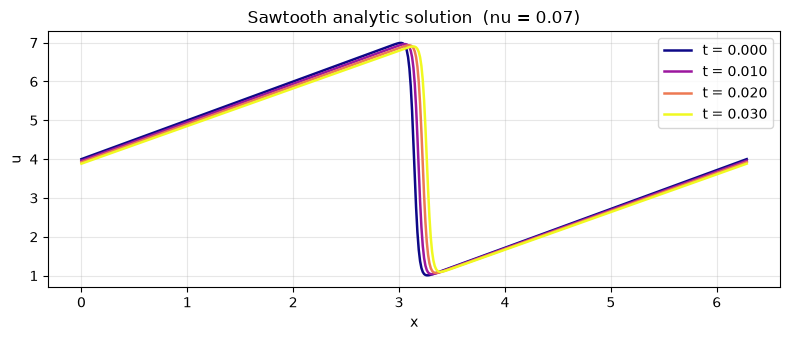

In [2]:
NU     = 0.07
X0, XF = 0.0, 2 * np.pi

def toothsaw(t, x):
    """Hopf-Cole analytic solution for viscous Burgers on [0, 2pi]."""
    x  = np.asarray(x, dtype=float)
    nu = NU
    c  = 4 * nu * (t + 1)
    a  = (-4*t + x)**2           / c
    b  = (-4*t + x - 2*np.pi)**2 / c
    num = ((-8*t + 2*x)            * np.exp(-a)
         + (-8*t + 2*x - 4*np.pi) * np.exp(-b)) / c
    den = np.exp(-b) + np.exp(-a)
    return 2 * nu * num / den + 4

x_plot = np.linspace(X0, XF, 500)
fig, ax = plt.subplots(figsize=(8, 3.5))
cmap = plt.cm.plasma
for i, t in enumerate([0.0, 0.01, 0.02, 0.03]):
    ax.plot(x_plot, toothsaw(t, x_plot), color=cmap(i / 3), lw=1.8, label=f't = {t:.3f}')
ax.set_xlabel('x'); ax.set_ylabel('u')
ax.set_title('Sawtooth analytic solution  (nu = 0.07)')
ax.legend(loc='upper right'); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 2. Experiment configuration

Architecture, scheme, and optimisation are fixed; only `collocation_fn` changes. `TOLERANCE = 1e-8` is
the framework trainer's early-stop threshold; `EPOCHS` is the per-step budget (also the cap when the
tolerance is not reached).

In [ ]:
ARCH        = 'MLP'
PARAMS_ARCH = {'layers': (1, 32, 32, 32, 1), 'activation': 'tanh'}

DT     = 0.005
T_END  = 0.025
NT     = round(T_END / DT)

EPOCHS     = 100000          # per-step budget / cap
TOLERANCE  = 1e-2          # absolute-loss early-stop threshold (kept fixed)
LR         = 1e-2
MAX_LR     = 1e-2          # peak / initial lr (scheduler starts here)
MIN_LR     = 1e-6          # scheduler decay floor (ReduceLROnPlateau)
IC_WEIGHT  = 15.0/( (15**2+5**2+1**2)**(1/2) )
BC_WEIGHT  = 5.0/( (15**2+5**2+1**2)**(1/2) )
PDE_WEIGHT = 1.0/( (15**2+5**2+1**2)**(1/2) )
N_COLLOC   = 500
N_EVAL     = 1000

STRATEGIES = {
    'uniform'       : collocation_uniform,
    'lhs'           : collocation_lhs,
    'gradient'      : collocation_gradient,
    'curvature'     : collocation_curvature,
    'last_residual' : collocation_last_residual,
    'mean_residual' : collocation_mean_residual,
}

times = [k * DT for k in range(NT + 1)]
print(f'{NT} PDE steps of dt={DT}  ->  T={T_END}   |   {len(STRATEGIES)} strategies')

5 PDE steps of dt=0.005  ->  T=0.025   |   6 strategies


## 3. IC / BC, residual, exact-solution evaluator

The time integrator is **Crank–Nicolson** ($O(\Delta t^2)$). With the spatial operator
$S(w) = w\,w_x - \nu\,w_{xx}$ the residual is $\frac{u-u^{t-1}}{\Delta t} + \tfrac12[S(u) + S(u^{t-1})]$.
The frozen previous step $S(u^{t-1})$ is differentiated (the framework keeps `u_prev`'s graph) and then
detached so no gradient reaches it.

In [4]:
x_ic_np = np.linspace(X0, XF, 201)
u_ic_np = toothsaw(0, x_ic_np)
x_ic = torch.tensor(x_ic_np, dtype=torch.float32).unsqueeze(1)
u_ic = torch.tensor(u_ic_np, dtype=torch.float32).unsqueeze(1)

u_bc_val = float(toothsaw(0, X0))
x_bc = torch.tensor([[X0], [XF]], dtype=torch.float32)
u_bc = torch.full((2, 1), u_bc_val, dtype=torch.float32)
print(f'IC range: [{u_ic.min():.3f}, {u_ic.max():.3f}]   BC value: {u_bc_val:.4f}')

x_dim = PINSpatialDimension('x', domain=(X0, XF), n_colloc=N_COLLOC)

def burgers_residual(u, u_prev, x, dt, nu):
    """Crank-Nicolson residual for viscous Burgers.  S(w) = w*w_x - nu*w_xx."""
    def S(w):
        w_x  = torch.autograd.grad(w.sum(),   x, create_graph=True)[0]
        w_xx = torch.autograd.grad(w_x.sum(), x, create_graph=True)[0]
        return w * w_x - nu * w_xx
    return (u - u_prev.detach()) / dt + 0.5 * (S(u) + S(u_prev).detach())

loss_fn = PINLossFunction([x_dim], burgers_residual)

def exact_fn(t, x_pts):
    u = toothsaw(t, x_pts.detach().cpu().numpy().ravel())
    return torch.tensor(u, dtype=torch.float32, device=x_pts.device).unsqueeze(1)

IC range: [1.006, 6.994]   BC value: 4.0000


## 4. Run every strategy with the native `PINTrainer`

For each strategy we build a fresh `PINTrainer` (same seed, so identical init), call `fit`, and then read
two things back:
- `trainer.step_history` → epochs used per step (and whether it hit the `1e-8` tolerance),
- `compute_metrics(...)` → $L_\infty$ per time level.

These reduce to one summary point per strategy.

In [ ]:
records = {}

for name, fn in STRATEGIES.items():
    torch.manual_seed(0); np.random.seed(0)
    net = PINArchitecture(ARCH, PARAMS_ARCH)
    trainer = PINTrainer(
        net=net, scheme='TD-PINNS', loss_fn=loss_fn, spatial_dims=[x_dim],
        epochs=EPOCHS, dt=DT, lr=LR, max_lr=MAX_LR, min_lr=MIN_LR, tolerance=TOLERANCE,
        ic_weight=IC_WEIGHT, bc_weight=BC_WEIGHT, pde_weight=PDE_WEIGHT,
        collocation_fn=fn, verbose=True, log_every=10000
    )
    t0 = time.perf_counter()
    nets = trainer.fit(x_ic=x_ic, u_ic=u_ic, x_bc=x_bc, u_bc=u_bc, T=T_END, nu=NU)
    wall = time.perf_counter() - t0

    pde_steps = trainer.step_history[1:]                      # skip the IC fit
    epochs_used = sum(h['epochs'] for h in pde_steps)          # total over PDE steps
    n_converged = sum(h['converged'] for h in pde_steps)
    df = compute_metrics(nets, times, [x_dim], n_eval=N_EVAL,
                         exact_fn=exact_fn, device=trainer.device)

    records[name] = {
        'epochs_used'  : epochs_used,
        'all_converged': n_converged == len(pde_steps),
        'n_converged'  : n_converged,
        'n_steps'      : len(pde_steps),
        'mean_Linf'    : float(df['Linf'].mean()),
        'final_Linf'   : float(df['Linf'].iloc[-1]),
        'wall_s'       : wall,
        'linf_series'  : df['Linf'],
        'nets'         : nets,
        'device'       : trainer.device,
    }
    print(f'{name:14s} | epochs {epochs_used:6d} | converged {n_converged}/{len(pde_steps)} '
          f'| mean Linf {df["Linf"].mean():.4e} | wall {wall:5.1f}s')

=== TD-PINNs | step 0 — initial condition ===
  [step 0 / IC] converged at epoch 861 | loss 9.7404e-04
=== TD-PINNs | step 1/5  (t = 0.005) ===
  [step 1] epoch 10000 | loss 2.4933e-02
  [step 1] epoch 20000 | loss 2.1842e-02
  [step 1] epoch 30000 | loss 2.0983e-02
  [step 1] epoch 40000 | loss 2.0655e-02
  [step 1] epoch 50000 | loss 1.9225e-02
  [step 1] epoch 60000 | loss 1.8459e-02
  [step 1] epoch 70000 | loss 1.6711e-02
  [step 1] epoch 80000 | loss 1.6269e-02
  [step 1] epoch 90000 | loss 1.6954e-02
  [step 1] epoch 100000 | loss 1.5403e-02
=== TD-PINNs | step 2/5  (t = 0.01) ===
  [step 2] epoch 10000 | loss 5.8744e-02


## 5. (epochs, $L_\infty$) — one point per strategy

x-axis: total epochs the PDE steps used to reach `TOLERANCE` (the cap, when not reached).
y-axis: mean $L_\infty$ error vs exact across time levels. **Lower-left is better.**

Each strategy gets its own **marker** (the convention is listed in the side table); markers are
**filled** when every step converged and **hollow** when at least one hit the cap. The figure is saved to
`figs/` as a PDF and also shown inline.

In [ ]:
import os

# ── Plot style: a distinct serif / Computer-Modern look ──────────────────
plt.rcParams.update({
    'font.family'     : 'serif',
    'font.serif'      : ['DejaVu Serif'],
    'mathtext.fontset': 'cm',
    'font.size'       : 12,
    'axes.titlesize'  : 13,
    'axes.labelsize'  : 12,
    'legend.fontsize' : 10,
})

# ── Marker convention: one marker per collocation strategy ───────────────
MARKERS = {
    'uniform'       : ('o', 'circle'),
    'lhs'           : ('s', 'square'),
    'gradient'      : ('^', 'triangle up'),
    'curvature'     : ('D', 'diamond'),
    'last_residual' : ('v', 'triangle down'),
    'mean_residual' : ('P', 'plus'),
}
colors   = plt.cm.tab10(np.linspace(0, 1, len(MARKERS)))
color_of = {name: colors[i] for i, name in enumerate(MARKERS)}

FIGDIR = 'figs'
os.makedirs(FIGDIR, exist_ok=True)

fig, (ax, ax_tab) = plt.subplots(
    1, 2, figsize=(12, 5.5), gridspec_kw={'width_ratios': [3, 1.7]})

for name, r in records.items():
    mk, _ = MARKERS[name]
    c     = color_of[name]
    face  = c if r['all_converged'] else 'none'
    ax.scatter(r['epochs_used'], r['mean_Linf'], s=170, marker=mk,
               color=c, facecolors=face, edgecolors=c, linewidths=2,
               zorder=3, label=name)

ax.set_yscale('log')
ax.set_xlabel('epochs used to reach tolerance  (total over PDE steps)')
ax.set_ylabel(r'mean $L_\infty$ error vs exact')
ax.set_title('TD-PINNs Burgers (Crank–Nicolson)\ncollocation strategies')
ax.grid(True, which='both', alpha=0.3)
ax.legend(title='strategy (marker)', loc='best')

# ── Convention + results table ───────────────────────────────────────────
ax_tab.axis('off')
rows = [n for n in MARKERS if n in records]
cell_text = [[MARKERS[n][1], f"{records[n]['mean_Linf']:.3f}", f"{records[n]['epochs_used']}"]
             for n in rows]
tbl = ax_tab.table(cellText=cell_text, rowLabels=rows,
                   colLabels=['marker', r'mean $L_\infty$', 'epochs'],
                   loc='center', cellLoc='center')
tbl.auto_set_font_size(False); tbl.set_fontsize(9); tbl.scale(1, 1.6)
for i, n in enumerate(rows):                      # colour row labels to match
    tbl[(i + 1, -1)].get_text().set_color(color_of[n])
ax_tab.set_title('convention  (filled = converged, hollow = hit cap)', fontsize=10)

plt.tight_layout()
savepath = os.path.join(FIGDIR, 'collocation_burgers_epochs_linf.pdf')
fig.savefig(savepath, bbox_inches='tight')
print('saved ->', savepath)
plt.show()

## 6. Summary table and per-level $L_\infty$

In [ ]:
summary = pd.DataFrame([
    {'strategy': n, 'epochs_used': r['epochs_used'],
     'converged': f"{r['n_converged']}/{r['n_steps']}",
     'mean_Linf': r['mean_Linf'], 'final_Linf': r['final_Linf'], 'wall_s': r['wall_s']}
    for n, r in records.items()
]).set_index('strategy').sort_values('mean_Linf')
pd.set_option('display.float_format', '{:.4e}'.format)
print('=== Collocation strategy summary (sorted by mean Linf) ===')
print(summary.to_string())
print(f'\nBest mean Linf: {summary.index[0]}')

=== Collocation strategy summary (sorted by mean Linf) ===
               epochs_used converged  mean_Linf  final_Linf     wall_s
strategy                                                              
uniform               4906       5/5 1.7308e+00  1.7048e+00 7.3420e+00
last_residual         4774       5/5 1.7610e+00  1.6869e+00 6.9411e+00
mean_residual         4774       5/5 1.7610e+00  1.6869e+00 6.9522e+00
lhs                   2461       5/5 1.7610e+00  1.8478e+00 3.7801e+00
gradient              4849       5/5 1.7667e+00  1.7012e+00 8.8728e+00
curvature             4521       5/5 1.8579e+00  1.8949e+00 8.3793e+00

Best mean Linf: uniform


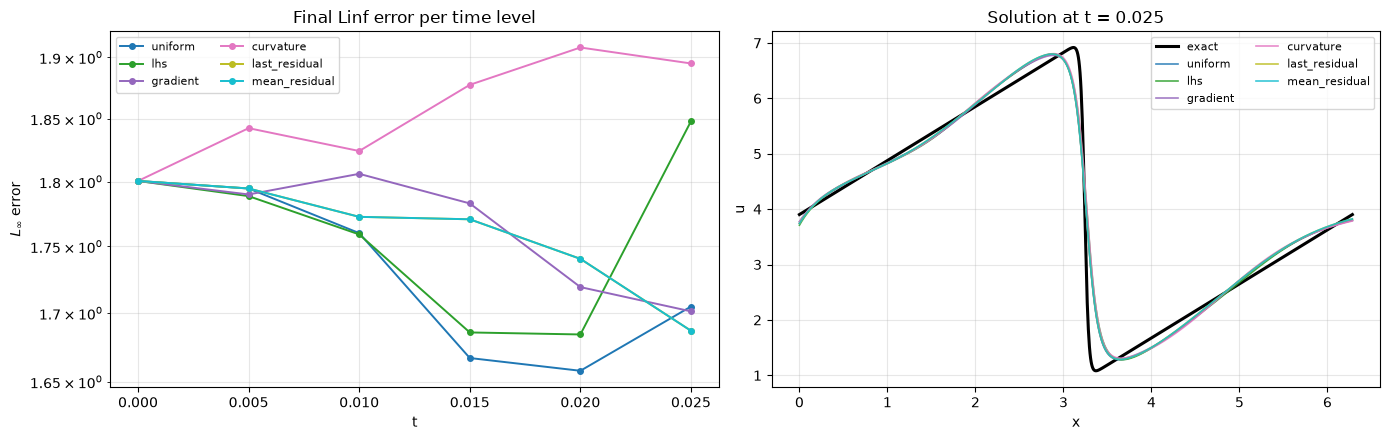

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

ax = axes[0]
for (name, r), c in zip(records.items(), colors):
    ax.semilogy(times, r['linf_series'].values, '-o', ms=4, lw=1.4, color=c, label=name)
ax.set_xlabel('t'); ax.set_ylabel(r'$L_\infty$ error')
ax.set_title('Final Linf error per time level')
ax.legend(ncol=2, fontsize=8); ax.grid(True, which='both', alpha=0.3)

ax = axes[1]
x_eval = torch.linspace(X0, XF, N_EVAL).unsqueeze(1)
xev_np = x_eval.numpy().ravel()
ax.plot(xev_np, toothsaw(T_END, xev_np), 'k-', lw=2.2, label='exact')
for (name, r), c in zip(records.items(), colors):
    net = r['nets'][-1].eval()
    with torch.no_grad():
        u = net(x_eval.to(r['device'])).cpu().numpy().ravel()
    ax.plot(xev_np, u, lw=1.2, color=c, alpha=0.85, label=name)
ax.set_xlabel('x'); ax.set_ylabel('u')
ax.set_title(f'Solution at t = {T_END:.3f}')
ax.legend(ncol=2, fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 7. Notes

- Uses the **native `PINTrainer`** (TD-PINNs / Crank–Nicolson) — no custom training loop. The framework
  additions used here are `step_history` (diagnostic epoch/convergence log), keeping `u_prev`'s graph
  (so CN can differentiate the frozen step), and the tunable `max_lr` / `min_lr` schedule.
- The comparison figure is written to `figs/collocation_burgers_epochs_linf.pdf` and shown inline; each
  strategy has a fixed marker (see the convention table), filled when all steps converged.
- Adaptive strategies place `adaptive_frac = 0.5` of points in high-importance regions; the residual-
  based ones (`last_/mean_residual`) fall back to uniform on the first step.